# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri. Dataset adalah data 'Energy Consumption Dataset - Linear Regression' yang diunduh dari public repositories Kaggle dengan url : https://www.kaggle.com/datasets/govindaramsriram/energy-consumption-dataset-linear-regression

2. **Informasi Dataset**:
   Dataset ini dirancang khusus untuk memprediksi konsumsi energi berdasarkan karakteristik bangunan dan faktor lingkungan. Informasi yang termuat di dalamnya meliputi variabel tipe bangunan, luas area persegi (square footage), jumlah penghuni, jenis peralatan elektronik yang digunakan, suhu rata-rata, hingga hari dalam seminggu. Seluruh atribut tersebut berfungsi sebagai variabel penentu untuk membangun model prediktif yang akurat dalam mengestimasi total penggunaan energi.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
 


C:\Users\USER\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
df = pd.read_csv("data/energy_data.csv")

In [3]:
print("Shape:", df.shape)

Shape: (1100, 7)


In [4]:
print("\nKolom:")
print(df.columns.tolist())


Kolom:
['Building Type', 'Square Footage', 'Number of Occupants', 'Appliances Used', 'Average Temperature', 'Day of Week', 'Energy Consumption']


In [5]:
df.head()

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1100 non-null   object 
 1   Square Footage       1100 non-null   int64  
 2   Number of Occupants  1100 non-null   int64  
 3   Appliances Used      1100 non-null   int64  
 4   Average Temperature  1100 non-null   float64
 5   Day of Week          1100 non-null   object 
 6   Energy Consumption   1100 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 60.3+ KB


In [7]:
df.describe()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,25500.527273,48.268182,25.730000,22.559745,4168.191273
std,14236.955632,29.127624,14.116209,7.122357,924.278723
min,560.000000,1.000000,1.000000,10.050000,1683.950000
25%,13203.750000,22.000000,13.000000,16.365000,3510.460000
50%,25785.500000,47.000000,26.000000,22.810000,4189.690000
75%,37536.750000,73.000000,38.000000,28.760000,4859.510000
max,49997.000000,99.000000,49.000000,34.990000,6530.600000


In [8]:
df.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

C:\Users\USER\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


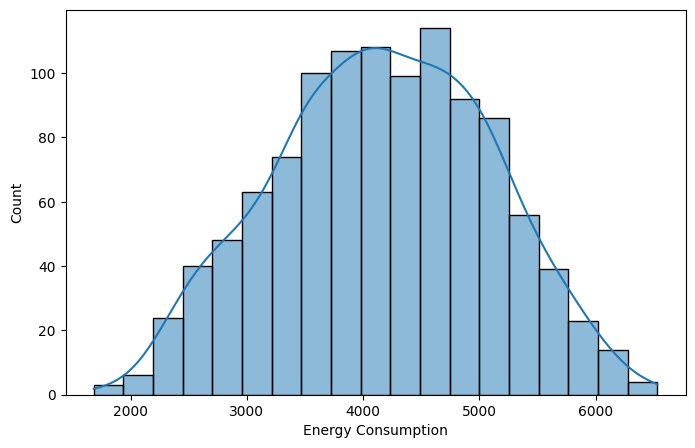

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df["Energy Consumption"], kde=True)
plt.show()

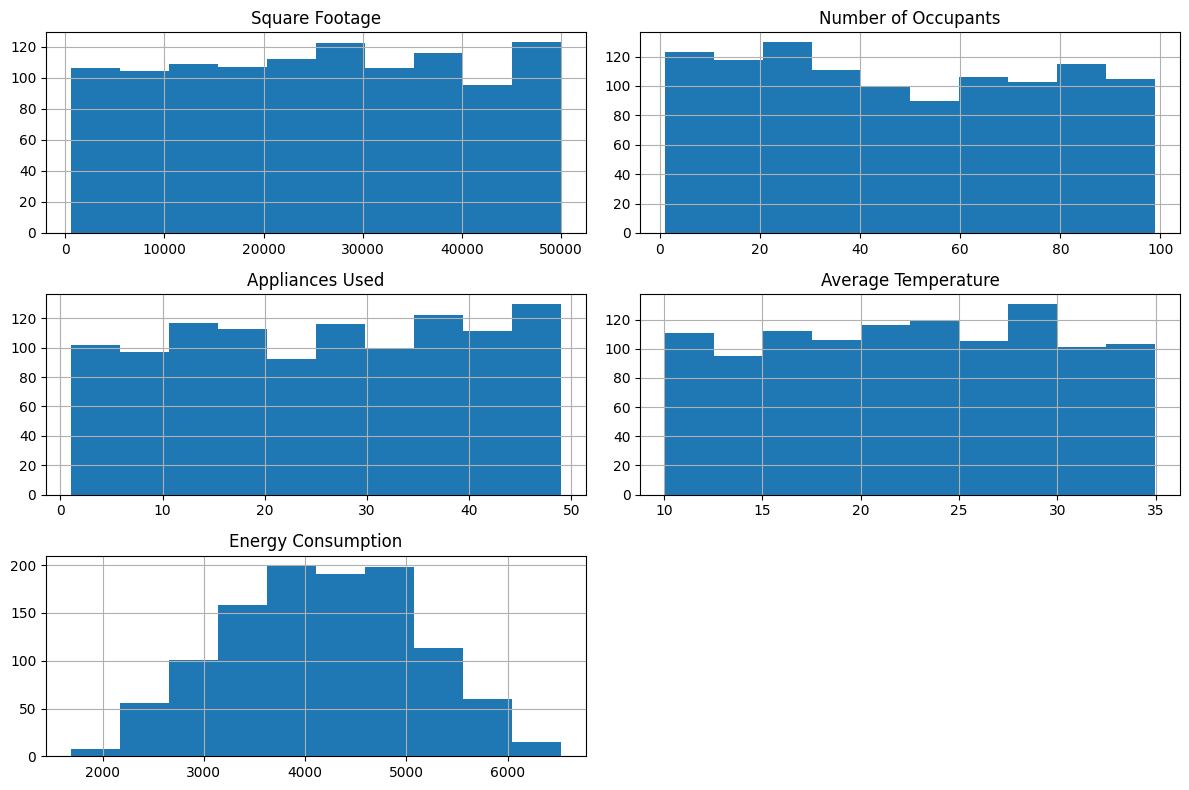

In [10]:
numerical_cols = [
    "Square Footage",
    "Number of Occupants",
    "Appliances Used",
    "Average Temperature",
    "Energy Consumption"
]

df[numerical_cols].hist(figsize=(12,8))
plt.tight_layout()
plt.show()

In [11]:
corr = df[numerical_cols].corr()

print(corr)

                     Square Footage  Number of Occupants  Appliances Used  \
Square Footage             1.000000             0.023133        -0.024825   
Number of Occupants        0.023133             1.000000         0.024318   
Appliances Used           -0.024825             0.024318         1.000000   
Average Temperature        0.027354             0.007351        -0.069989   
Energy Consumption         0.770765             0.350280         0.301505   

                     Average Temperature  Energy Consumption  
Square Footage                  0.027354            0.770765  
Number of Occupants             0.007351            0.350280  
Appliances Used                -0.069989            0.301505  
Average Temperature             1.000000           -0.038206  
Energy Consumption             -0.038206            1.000000  


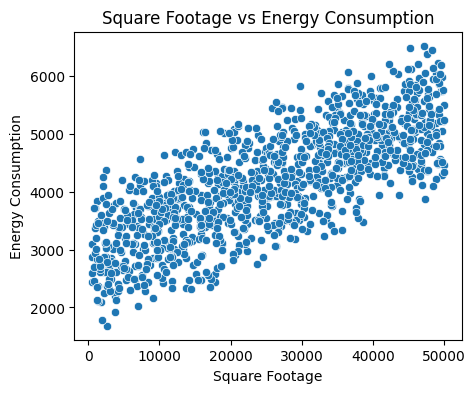

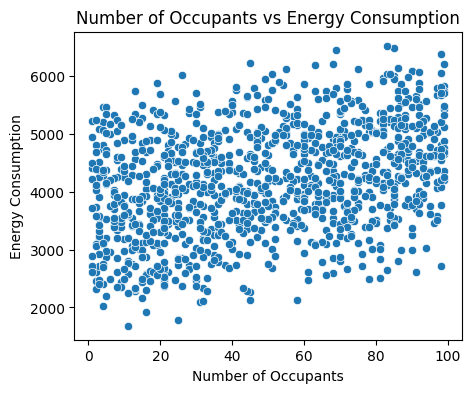

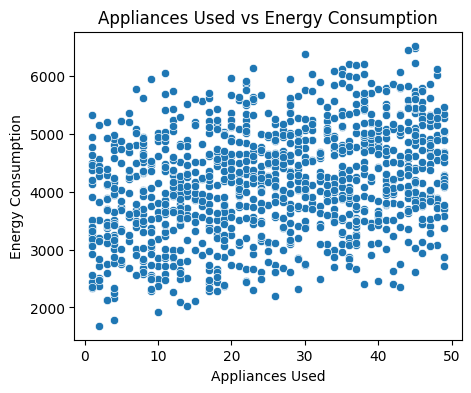

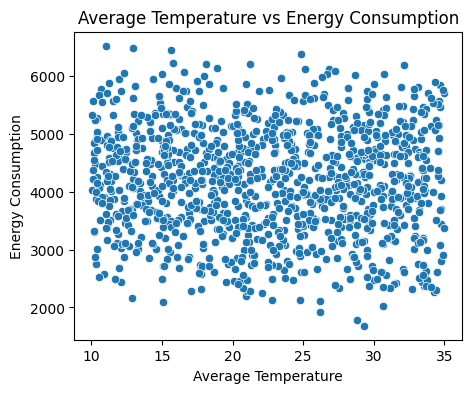

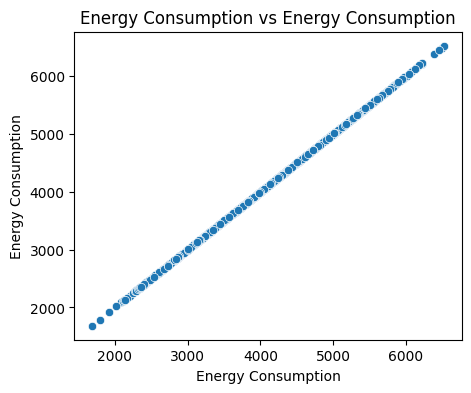

In [12]:
for col in numerical_cols:
    plt.figure(figsize=(5,4))
    sns.scatterplot(data=df, x=col, y="Energy Consumption")
    plt.title(f"{col} vs Energy Consumption")
    plt.show()

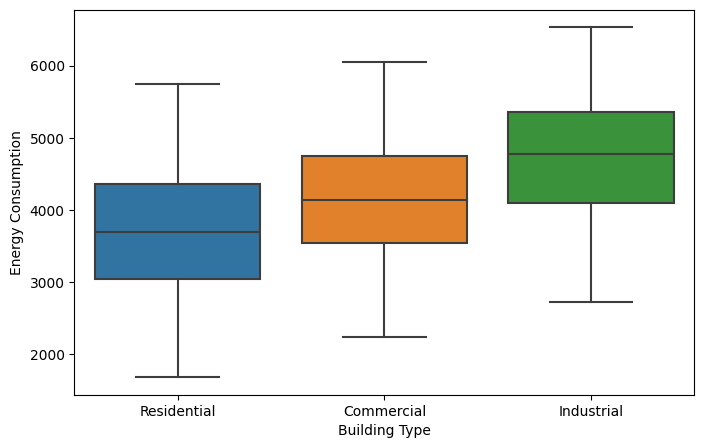

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Building Type",
    y="Energy Consumption"
)

plt.show()

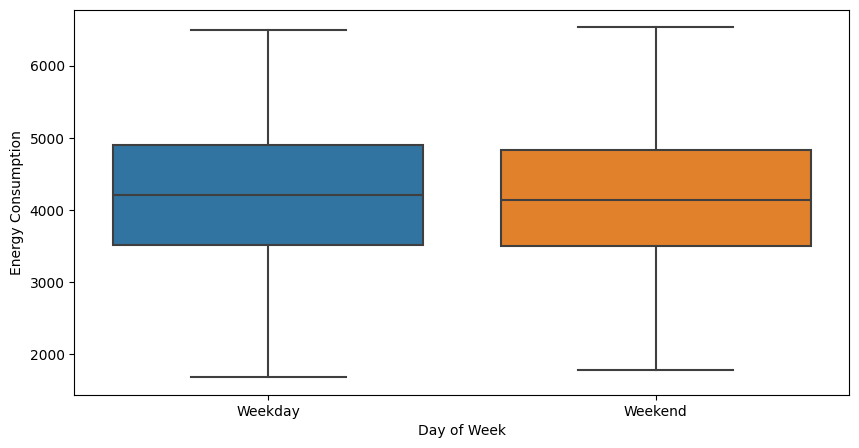

In [14]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="Day of Week",
    y="Energy Consumption"
)

plt.show()

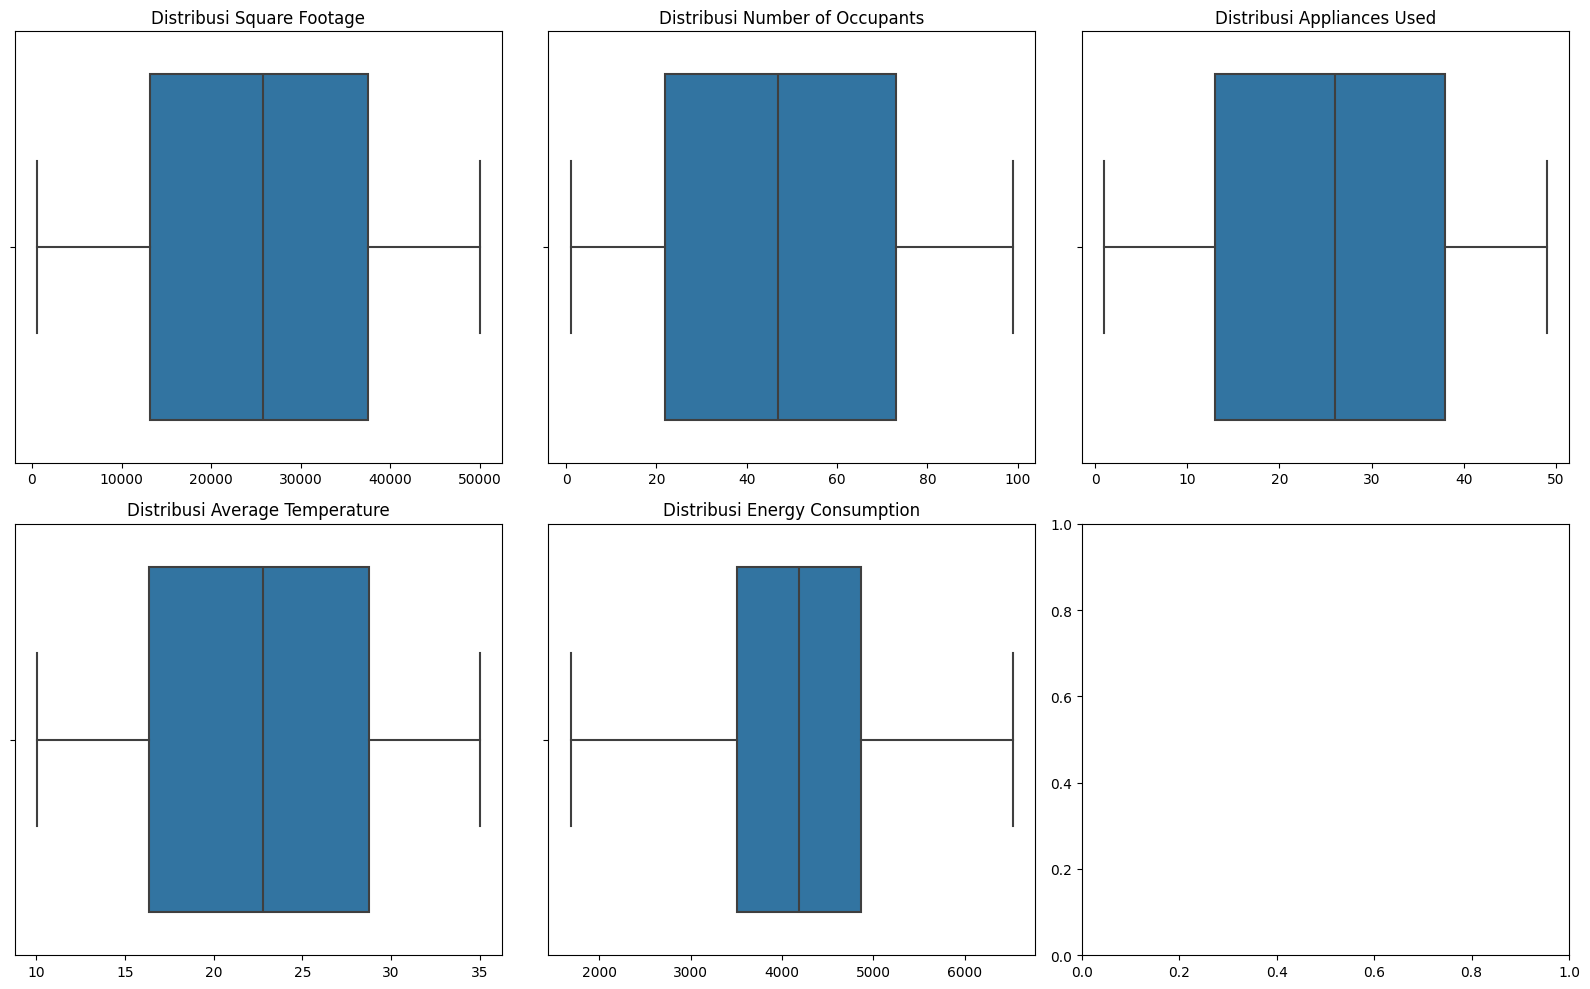

In [15]:
nrows = 2
ncols = 3
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 10))

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    
    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel("")  


plt.tight_layout()
plt.show()

In [16]:
outlier_indices = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    outlier_indices.extend(outliers.index)
    
    percentage = (len(outliers) / len(df)) * 100
    print(f"Kolom '{col}':")
    print(f"  - Jumlah Outlier: {len(outliers)} baris")

Kolom 'Square Footage':
  - Jumlah Outlier: 0 baris
Kolom 'Number of Occupants':
  - Jumlah Outlier: 0 baris
Kolom 'Appliances Used':
  - Jumlah Outlier: 0 baris
Kolom 'Average Temperature':
  - Jumlah Outlier: 0 baris
Kolom 'Energy Consumption':
  - Jumlah Outlier: 0 baris


Dari eksplorasi data yang telah dilakukan, ditemukan 1100 sampel dengan missing value sebanyak 0. Terdapat perbedaan yang sangat besar dari skala variabel "Square Foot Fotage" dengan variabel lainnya sehingga dirasa diperlukan penyesuaian agar tiap variabel memiliki skala yang seragam. Dari nilai korelasi tiap variabel didapatkan bahwa variabel "Square Foot Fotage" memiliki korelasi yang cukup tinggi terhadap "Energy Consumption", sedangkan "average Temperature" dirasa tidak memiliki hubungan linear dengan "Energy Consumption". Variabel "Building Type" juga dirasa memiliki pengaruh terhadap distribusi "Energy Consumption", sedangkan distribusi "Energy Consumption" pada tiap jenis"Day of Week" dirasa tidak memiliki perbedaan. Dari Boxplot variabel numerik yang dibuat dan perhitungan IQR tidak terlihat adanya outlier pada tiap variabel numerik.     

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [17]:
df = df.drop_duplicates()

In [18]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

for col in numerical_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

for col in categorical_cols:
    if len(df[col].mode()) > 0:
        mode_val = df[col].mode()[0] # .mode() mengembalikan Series, ambil indeks ke-0
        df[col] = df[col].fillna(mode_val)

In [19]:
numerical_features = [
    "Square Footage",
    "Number of Occupants",
    "Appliances Used",
    "Average Temperature"
]

scaler = StandardScaler()

df[numerical_features] = scaler.fit_transform(df[numerical_features])

print(df[numerical_features].describe()) 

       Square Footage  Number of Occupants  Appliances Used  \
count    1.100000e+03         1.100000e+03     1.100000e+03   
mean     9.689219e-17         8.235836e-17    -2.906766e-17   
std      1.000455e+00         1.000455e+00     1.000455e+00   
min     -1.752613e+00        -1.623534e+00    -1.752684e+00   
25%     -8.641153e-01        -9.022408e-01    -9.022104e-01   
50%      2.002551e-02        -4.355861e-02     1.913565e-02   
75%      8.458056e-01         8.494709e-01     8.696089e-01   
max      1.721408e+00         1.742500e+00     1.649209e+00   

       Average Temperature  
count         1.100000e+03  
mean         -3.148996e-16  
std           1.000455e+00  
min          -1.757204e+00  
25%          -8.701562e-01  
50%           3.515246e-02  
75%           8.709301e-01  
max           1.746038e+00  


In [20]:
categorical_cols = ['Building Type', 'Day of Week']

encoder = OneHotEncoder(drop='first', sparse_output=False, dtype=int)

encoded_array = encoder.fit_transform(df[categorical_cols])

encoded_col_names = encoder.get_feature_names_out(categorical_cols)

df_encoded_cols = pd.DataFrame(encoded_array, columns=encoded_col_names, index=df.index)

df_final = df.drop(columns=categorical_cols)
df_final = pd.concat([df_final, df_encoded_cols], axis=1)

print(df_final.head())

   Square Footage  Number of Occupants  Appliances Used  Average Temperature  \
0       -1.295636             0.952513        -1.114829             1.022634   
1        1.326130             0.609040         1.365718            -0.820291   
2       -0.438884            -0.387031        -0.618719            -1.160220   
3       -0.859811            -1.177019         1.082227             1.441225   
4       -0.852081            -0.764852        -0.547847            -1.494531   

   Energy Consumption  Building Type_Industrial  Building Type_Residential  \
0             2713.95                         0                          1   
1             5744.99                         0                          0   
2             4101.24                         1                          0   
3             3009.14                         0                          1   
4             3279.17                         0                          0   

   Day of Week_Weekend  
0                    0  


In [21]:
#df_final.to_csv("energy_consumption_preprocessing.csv", index=False)

In [22]:
!pipreqs . --force

INFO: Not scanning for jupyter notebooks.
INFO: Successfully saved requirements file in .\requirements.txt
